# Case study 1 revisited: a fold-transversal logical Hadamard, verified with syndrome measurement

The thesis verified the fold-transversal Hadamard protocol on the distance-3 surface code by **post-selecting every measurement outcome to 0** and running PyZX's `full_reduce`, which collapsed the whole protocol to a single Hadamard box. Here the same protocol is verified with the outcomes kept **symbolic** (Boolean variables `c[i]`), using the generalized parity form with phases (`zxqec.gpf`). The result is stronger:

* the protocol reduces to a Hadamard **plus an outcome-dependent Pauli frame** — the corrections a decoder would apply;
* the reduction also produces the **detectors**: the parities of outcomes that are always 0 in the noiseless circuit;
* setting all outcomes to 0 recovers exactly the thesis's result.

The protocol (thesis §4.6): encode the logical qubit and run an X-check round (code 1); apply a transversal Hadamard, which moves the information to the dual code; run a QEC round of code 2; rotate the data grid by 90°, which maps the dual code's boundaries back onto the original layout; run QEC rounds of code 1 and decode. The circuit files are in `circuits/ft_h/` (see the README there for the qubit roles).

In [1]:
import os, random, time
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import HAD, Reset
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram
from zxqec.spacetime import Topology, draw_program_web, draw_program_3d
from zxqec.gpf import reduce_gpf, boolean_variables, has_boundary_hadamard, is_gpf, sample_consistent_assignment

N, BITS = 19, 35
X_ANC, Z_ANC = [10, 11, 12, 13], [14, 15, 16, 17]

def load(name):
    return zx.Circuit.load(os.path.join("circuits", "ft_h", name + ".qasm"))

def with_prefix(circ, gates):
    """``gates`` (ancilla preparations) followed by ``circ``."""
    c = Circuit(N, bit_amount=BITS)
    for g in gates:
        c.add_gate(g)
    c.add_circuit(circ)
    return c

## 1. The protocol as a `QProgram`

Data qubits and the decode ancilla start in $|0\rangle$, the check ancillas in $|+\rangle$; the logical input `q[0]` stays open. The circuit files reuse ancillas after measuring them without re-preparing them, so a `reset` (and an `h` for the X checks) is added at the start of the stages that reuse them. The stages after the rotation are written in the **physical frame** — "qubit 1" means the position in the grid — which `add_circuit(..., physical=True)` translates into the logical qubits currently sitting there.

In [2]:
p = QProgram(N, bits=BITS,
             initial_states={**{q: '0' for q in range(1, 10)}, 18: '0', **{a: '+' for a in X_ANC + Z_ANC}})
p.add_circuit(load("ft_h"), name="encode + X checks")
p.add_circuit(load("ft_h_2"), name="transversal H")
p.add_circuit(with_prefix(load("ft_h_3"), [Reset(a) for a in X_ANC]), name="Z checks (code 2)")
p.add_circuit(load("ft_h_3.2"), name="X checks (code 2)")
p.add_permutation([0, 3, 6, 9, 2, 5, 8, 1, 4, 7] + list(range(10, 19)), name="rotate 90°")
p.add_circuit(with_prefix(load("ft_h_5"), [Reset(a) for a in Z_ANC]), name="Z checks", physical=True)
p.add_circuit(with_prefix(load("ft_h_5.2"), [g for a in X_ANC for g in (Reset(a), HAD(a))]), name="X checks", physical=True)
p.add_circuit(with_prefix(load("ft_h_6"), [Reset(a) for a in Z_ANC]), name="Z checks + decode", physical=True)

g = p.quantum_graph()          # the master graph without the (inert) classical-bit wires
print(sum(1 for v in g.vertices() if g.type(v) != VertexType.BOUNDARY), "spiders;",
      "inputs", g.inputs(), "outputs", g.outputs())
print(len(boolean_variables(g)), "measurement outcomes as Boolean variables")
print(p.describe_level(0))

311 spiders; inputs (0,) outputs (347,)
34 measurement outcomes as Boolean variables
Level 0 (8 blocks):
  Block 0 'encode + X checks': [encode + X checks]
  Block 1 'transversal H': [transversal H]
  Block 2 'Z checks (code 2)': [Z checks (code 2)]
  Block 3 'X checks (code 2)': [X checks (code 2)]
  Block 4 'rotate 90°': [rotate 90°]
  Block 5 'Z checks': [Z checks]
  Block 6 'X checks': [X checks]
  Block 7 'Z checks + decode': [Z checks + decode]


The whole protocol on a time axis, one shade per stage (the rotation is the narrow stage in the middle where the data wires cross); drag spiders, wheel to zoom:

In [3]:
draw_program_web(p, level=0, vdata=())      # per-spider timestep labels off: too dense for 300 spiders

The same on the thesis's layout of the 19 qubits (the 3×3 data grid with the check ancillas between the plaquettes), time upwards, one slab per stage:

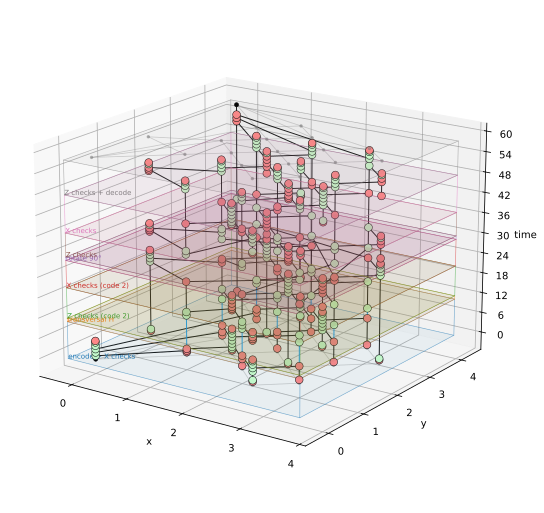

In [4]:
coords = {0: (0, 0), 1: (1, 1), 2: (2, 1), 3: (3, 1), 4: (1, 2), 5: (2, 2), 6: (3, 2), 7: (1, 3), 8: (2, 3), 9: (3, 3),
          10: (2.5, 0.5), 11: (1.5, 1.5), 12: (2.5, 2.5), 13: (1.5, 3.5), 14: (0, 1.5), 15: (2.5, 1.5), 16: (1.5, 2.5), 17: (3.5, 2.5), 18: (0, 4)}
topo = Topology(2)
for n, c in coords.items():
    topo.add_node(n, c)
for a, b in [(1, 11), (2, 11), (4, 11), (5, 11), (2, 10), (3, 10), (5, 12), (6, 12), (8, 12), (9, 12), (7, 13), (8, 13),
             (1, 14), (4, 14), (2, 15), (3, 15), (5, 15), (6, 15), (4, 16), (5, 16), (7, 16), (8, 16), (6, 17), (9, 17),
             (0, 1), (0, 4), (0, 7), (7, 18), (8, 18), (9, 18)]:
    topo.add_edge(a, b)
p.topology = topo
draw_program_3d(p, level=0, figsize=(10, 9), show_phases=False, elev=18, azim=-55)

## 2. Reduction to generalized parity form with phases

`reduce_gpf` brings the 300-spider master graph into a bipartite Z/X form and row-reduces both layers over GF(2), carrying the outcome-dependent Pauli phases along. A row that empties out is the scalar $1 + (-1)^p$, which forces $p = 0$: a **detector**.

In [5]:
t0 = time.time()
res = reduce_gpf(g, isolate_paulis = False)
r = res.graph
print(f"reduced in {time.time() - t0:.2f}s; GPF shape: {is_gpf(r)}; zero diagram: {res.is_zero}")
for v in sorted(r.vertices()):
    tag = " (Hadamard on this wire)" if r.type(v) == VertexType.BOUNDARY and has_boundary_hadamard(r, v) else ""
    print(f"  {VertexType(r.type(v)).name:<8} phase = {r.phase(v)}{tag}")
zx.draw(res.to_graph())

reduced in 0.04s; GPF shape: True; zero diagram: False
  BOUNDARY phase = 0
  Z        phase = c[0] + c[3] + c[4] + c[1] + c[2]
  BOUNDARY phase = 0 (Hadamard on this wire)
  X        phase = c[32] + c[29] + c[26]


The logical operation is a Hadamard (the Hadamard edge at the output) with a **Pauli frame**: a Z correction determined by the injection outcome `c[0]` and the first X-check round `c[1]`–`c[4]` (the fan-out state is not an eigenstate of the X checks, so their outcomes are random and each flips the logical Z frame), and an X correction given by `c[26]+c[29]+c[32]`, the final X-basis readout of one column of the data grid — the logical X operator. These are exactly the corrections a decoder applies in the noiseless case. Only 8 of the 34 outcomes appear in the diagram, and only through these two parities; §3 says what happens to each of the others.

The detectors:

In [6]:
for c in res.constraints:
    print("  ", c, "= 0")
print(len(res.constraints), "detectors")

   c[9] = 0
   c[11] = 0
   c[10] = 0
   c[12] = 0
   c[6] + c[2] = 0
   c[5] + c[1] = 0
   c[7] + c[4] = 0
   c[8] + c[3] = 0
   c[13] + c[3] = 0
   c[14] + c[1] = 0
   c[15] + c[4] = 0
   c[16] + c[2] = 0
   c[18] = 0
   c[17] = 0
   c[19] = 0
   c[20] = 0
   c[21] + c[3] = 0
   c[22] + c[1] = 0
   c[23] + c[4] = 0
   c[24] + c[2] = 0
   c[28] + c[27] = 0
   c[30] + c[29] + c[27] + c[26] = 0
   c[33] + c[32] = 0
   c[34] + c[32] + c[31] + c[29] + c[27] + c[26] = 0
24 detectors


Reading them: `c[9]`–`c[12]` and `c[17]`–`c[20]` are checks whose outcome is deterministic on the prepared state; `c[6]+c[2]`, `c[5]+c[1]`, … say that a check repeated in a later round (after the transversal Hadamard, or after the rotation) must give the same outcome as the first X-check round; the last four are X stabilizers read off the final data measurements.

**A wiring error found by the symbolic analysis.** Run on the thesis's original circuit files, this reduction gave 22 detectors and two anomalies:

* `c[13]`, an ancilla check in the middle of the protocol (q14, stage 5), appeared in no detector and in no phase — a random outcome that is never re-checked and affects nothing. In a correct noiseless protocol that cannot happen: every mid-circuit check measures a stabilizer, so its outcome is either deterministic or equal to the value the same operator had when it was last measured.
* `c[18]`, the X check on positions 2 and 3, was random and in the Pauli frame, while its three siblings in the same round were deterministic 0. An X check can only turn random if something anticommuting with it was measured in between.

The only measurements in between are the stage-5 Z checks, and a genuine CSS Z stabilizer commutes with every X stabilizer — so one of them was not a stabilizer, and the first anomaly named its ancilla. The file confirms it: `ft_h_5.qasm` wired q14 to positions 1 and 2, i.e. $Z_1Z_2$ (odd overlap with $X_2X_3$, as predicted), where every other stage wires it to positions 1 and 4. Changing that one character gives 24 detectors, `c[13] = c[3]`, `c[18] = 0`, and every outcome accounted for.

Post-selection cannot see this: $Z_1Z_2$ lies outside the normalizer of the stabilizer group, so a logical representative commuting with it exists ($X_L \cdot X_2X_3$), the logical information survives, and the protocol still gives `H` — it just accepts a quarter as often. What the bad check damages is the code, not the map: it randomises one stabilizer and costs two detectors. The file is corrected here (see `circuits/ft_h/README.md`).

### Where the other 26 variables went

No rewrite rule removes a variable: fusion adds phases mod 2, the Boolean bialgebra rule copies them, and a row addition is a change of summation variable that adds the phases too. A variable can only leave the graph when a spider is left with no edges: an isolated spider $Z(\pi p)$ or $X(\pi p)$ is the scalar $1 + e^{i\pi p} = 1 + (-1)^p$, which PyZX's `remove_isolated_vertices` records in `g.scalar` — that factor is $2$ when $p = 0$ and $0$ when $p = 1$, i.e. exactly a detector. The full statement is therefore

$$D(c) \;=\; \lambda(c)\,\prod_{k=1}^{24}\bigl(1 + (-1)^{p_k(c)}\bigr)\, D_{\mathrm{red}}(c), \qquad \lambda(c) \neq 0 .$$

`TrackingOutcomeVariables.ipynb` follows individual variables through every rewrite of both pipelines and shows this happening. The quickest independent check here is that PyZX's own simplifier, which never applies the Boolean bialgebra rule, accumulates the same factors in its scalar:

In [7]:
import re
VAR = re.compile(r'c\[\d+\]')

def gf2_rank(polys):                                   # rank over GF(2) of a list of Boolean parities
    names = sorted({v for p in polys for v in VAR.findall(str(p))})
    rows = []
    for p in polys:
        r = [0] * len(names)
        for v in VAR.findall(str(p)):
            r[names.index(v)] ^= 1
        rows.append(r)
    rank = 0
    for col in range(len(names)):
        piv = next((k for k in range(rank, len(rows)) if rows[k][col]), None)
        if piv is None:
            continue
        rows[rank], rows[piv] = rows[piv], rows[rank]
        for k in range(len(rows)):
            if k != rank and rows[k][col]:
                rows[k] = [a ^ b for a, b in zip(rows[k], rows[rank])]
        rank += 1
    return rank

fr = g.copy(); zx.full_reduce(fr)                      # PyZX's simplifier on the symbolic master graph
pz = list(fr.scalar.phasenodes)                        # every factor 1 + e^{i pi p} it met
print(f"full_reduce leaves {sum(1 for v in fr.vertices() if fr.type(v) != VertexType.BOUNDARY)} spiders "
      f"and {len(pz)} phase nodes in g.scalar")
print("same GF(2) span as our detectors:",
      gf2_rank(pz) == gf2_rank(res.detectors) == gf2_rank(pz + res.detectors))

full_reduce leaves 18 spiders and 24 phase nodes in g.scalar
same GF(2) span as our detectors: True


### The thesis pipeline on the same diagram

`isolate_paulis=True` reproduces the thesis's Algorithm 2: *every* non-zero phase is unfused into a gadget, the Pauli ones included. With symbolic outcomes each of the 34 `X(π c[i])` spiders becomes a leaf whose stem anchors its row, so the row reduction may not eliminate anything next to a measurement. The result is a correct diagram but not a reduced one — 96 vertices and no detectors — and since the sanity checks of section 3 draw their outcomes from the detectors, they cannot be run on it. Keeping the Pauli phases on the spiders is what turns this into `H` + Pauli frame + 24 detectors. (On the all-zero, phase-free diagram of the thesis both modes give the same 4-vertex result.)


In [8]:
res_thesis = reduce_gpf(g, isolate_paulis=True)      # the thesis pipeline: every non-zero phase becomes a gadget
print(f"{'':30}{'vertices':>10}{'detectors':>11}")
print(f"{'phases stay on spiders':30}{res.graph.num_vertices():>10}{len(res.detectors):>11}")
print(f"{'isolate_paulis=True (thesis)':30}{res_thesis.graph.num_vertices():>10}{len(res_thesis.detectors):>11}")
a = sample_consistent_assignment(res.constraints, boolean_variables(g), random.Random(0))   # a possible outcome, from the detectors above
ga = g.substitute_variables(a); zx.full_reduce(ga)
print("on a possible outcome the thesis-mode diagram still agrees with full_reduce(master):",
      zx.compare_tensors(ga, res_thesis.to_graph().substitute_variables(a), preserve_scalar=False))
zx.draw(res_thesis.to_graph())


                                vertices  detectors
phases stay on spiders                 4         24
isolate_paulis=True (thesis)          96          0
on a possible outcome the thesis-mode diagram still agrees with full_reduce(master): True


## 3. The measurement report

`p.measurement_report()` turns the reduction into the table a user of the protocol wants: for each measurement, where it was taken and what happens to it in the error-free setting — the map depends on it (**frame**), a detector fixes its value (**fixed**), the detectors tie it to other outcomes (**tied**), or nothing constrains it and nothing depends on it (**gauge**).

In [9]:
rep = p.measurement_report()
print(rep.summary())
print()
print(rep.table())

34 measurements in the whole diagram; Pauli frame: Z(c[0] + c[3] + c[4] + c[1] + c[2]), X(c[32] + c[29] + c[26])
8 frame; 8 fixed; 18 tied
24 detectors (24 of them internal); outcome space of the diagram: 24 forced + 2 steering the map + 8 gauge = 34

outcome  stage  qubit  pos  t   fate   why
c[0]     0      0      0    4   frame  the map depends on it: Z correction, with c[1], c[2], c[3], c[4]
c[1]     0      11     11   6   frame  the map depends on it: Z correction, with c[0], c[2], c[3], c[4]
c[2]     0      10     10   6   frame  the map depends on it: Z correction, with c[0], c[1], c[3], c[4]
c[3]     0      13     13   6   frame  the map depends on it: Z correction, with c[0], c[1], c[2], c[4]
c[4]     0      12     12   10  frame  the map depends on it: Z correction, with c[0], c[1], c[2], c[3]
c[6]     2      10     10   14  tied   its parity with c[2] (stage 0, qubit 10, t=6) is deterministic (c[6] + c[2] = 0)
c[5]     2      11     11   16  tied   its parity with c[1] (stag

Reading the columns: `qubit` is the logical qubit, `pos` the physical position it sat on — they differ after the rotation (`c[28]` is logical qubit 1 at position 3). The `why` column phrases each fate in terms of the protocol's own measurements.

Two cautions about the counting in the summary line. It is in **dimensions** of the outcome space, not in variable names: `24 forced + 2 steering the map + 8 gauge = 34`. The Pauli frame mentions eight names but is only two independent parities — flipping `c[26]` and `c[29]` together does not change the map. And *gauge* is a direction, not a name: in this protocol every variable appears in some detector or in the frame, yet 8 of the 10 free dimensions have no effect on the map.

Given the outcomes of a run it answers the decoder's two questions: which detectors fired, and which Pauli correction to apply.

In [10]:
shot = {n: 0 for n in rep.measurements}                  # an all-zero run
print("all-zero run  : violated", rep.violated(shot), " frame", rep.frame_values(shot), " possible", rep.is_possible(shot))
shot = dict(shot, **{'c[1]': 1, 'c[5]': 1, 'c[14]': 1, 'c[22]': 1})    # a consistent random run
print("consistent run: violated", rep.violated(shot), " frame", rep.frame_values(shot), " possible", rep.is_possible(shot))
shot = dict(shot, **{'c[9]': 1})                          # a deterministic check came out 1
print("faulty run    : violated", [str(d) for d in rep.violated(shot)], " possible", rep.is_possible(shot))

all-zero run  : violated []  frame [('Z', 0), ('X', 0)]  possible True
consistent run: violated []  frame [('Z', 1), ('X', 0)]  possible True
faulty run    : violated ['c[9]']  possible False


And for a block of a level — the measurements of one QEC round, classified in the context of the whole protocol, with the detectors that round can check on its own:

In [11]:
block = p.measurement_report(0, 2)                        # stage 2: the Z checks of code 2
print(block.summary())
print(block.table())
print("\ndetectors this block can check without the rest of the program:", block.internal_detectors())

4 measurements in block 2 of level 0 (Z checks (code 2)); Pauli frame: Z(c[0] + c[3] + c[4] + c[1] + c[2]), X(c[32] + c[29] + c[26])
4 tied
4 detectors (0 of them internal); outcome space of the diagram: 24 forced + 2 steering the map + 8 gauge = 34
outcome  stage  qubit  pos  t   fate  why
c[6]     2      10     10   14  tied  its parity with c[2] is deterministic (c[6] + c[2] = 0)
c[5]     2      11     11   16  tied  its parity with c[1] is deterministic (c[5] + c[1] = 0)
c[7]     2      12     12   20  tied  its parity with c[4] is deterministic (c[7] + c[4] = 0)
c[8]     2      13     13   20  tied  its parity with c[3] is deterministic (c[8] + c[3] = 0)

detectors this block can check without the rest of the program: []


### Detectors without a Clifford circuit

The reduction never assumes the circuit is Clifford: a non-Pauli phase becomes a gadget and simply never enters a detector. Whether a check still gives a detector then depends on where the non-Clifford gate sits — inside the check's support or beside it. Below, the same $Z_0Z_1$-style parity check is measured twice with a $T$ in between, once on a spectator qubit and once on a qubit the check acts on.

In [12]:
from pyzx.circuit.gates import CNOT, Measurement, T

def parity_round(n, bit):                     # one X_0 X_1 check with ancilla qubit 2
    c = Circuit(n, bit_amount=4)
    for gate in [Reset(2), HAD(2), CNOT(2, 0), CNOT(2, 1), HAD(2), Measurement(2, bit)]:
        c.add_gate(gate)
    return c

def two_rounds(n, t_on):                      # ... twice, with a T on qubit `t_on` in between
    q = QProgram(n, bits=4, initial_states={2: '0'})
    q.add_circuit(parity_round(n, 0), name="round 1")
    layer = Circuit(n, bit_amount=4); layer.add_gate(T(t_on))
    q.add_circuit(layer, name=f"T on qubit {t_on}")
    q.add_circuit(parity_round(n, 1), name="round 2")
    return q.measurement_report()

for n, t_on, where in [(4, 3, "a spectator qubit"), (3, 0, "a qubit the check acts on")]:
    r = two_rounds(n, t_on)
    detectors = ", ".join(str(d) for d in r.detectors) or "none"
    fates = ", ".join(f"{name}: {m.kind}" for name, m in r.measurements.items())
    print(f"T on {where:27}  detectors: {detectors:14}  {fates}")

T on a spectator qubit            detectors: c[1] + c[0]     c[0]: frame, c[1]: tied
T on a qubit the check acts on    detectors: none            c[0]: frame, c[1]: frame


On a spectator the check still repeats, so `c[1] = c[0]` survives as a detector — a statement stim could not make about this circuit, since it is not Clifford. Inside the support the $T$ destroys the repeatability, and the reduction correctly reports no detector: both outcomes become independent random bits that the map depends on.

### What the report cannot say yet

It classifies every outcome and relates them to each other, but it does not know **which operator** a measurement measures. That is why the `why` column above says "its parity with `c[1]` is deterministic" rather than "it measures the stabilizer $X_1X_2X_4X_5$, which the transversal Hadamard mapped from the check measured at $t=6$", and why the library cannot yet name the code the circuit is running.

Closing that gap needs a Clifford tableau that propagates each measurement's Pauli back through the stage circuits (planned as `zxqec.tableau`). With it, the fates line up with operators — *tied* ⇔ the two measurements propagate to the same Pauli, *fixed* ⇔ that Pauli is a stabilizer of the prepared state, *frame* ⇔ it is logical — the stabilizer group in force at each time can be read off, and each detector gains a name, a type and a space-time location.

## 4. Sanity checks

With every outcome set to 0 the reduced diagram is exactly a Hadamard — the thesis's post-selected statement — and PyZX's `full_reduce` on the original master graph agrees:


In [13]:
h_gate = Circuit(1); h_gate.add_gate(HAD(0))
zero = {n: 0 for n in boolean_variables(g)}
print("reduced diagram at all-zero outcomes == H       :", zx.compare_tensors(res.to_graph().substitute_variables(zero), h_gate.to_graph(), preserve_scalar=False))
g0 = g.substitute_variables(zero)
zx.full_reduce(g0)
print("full_reduce of the master graph at all-zero == H:", zx.compare_tensors(g0, h_gate.to_graph(), preserve_scalar=False))

reduced diagram at all-zero outcomes == H       : True
full_reduce of the master graph at all-zero == H: True


For outcome assignments that satisfy the detectors, the reduced diagram agrees with `full_reduce` of the full master graph (a Clifford-complete, independent computation):

In [14]:
rng = random.Random(1)
names = boolean_variables(g)
for trial in range(4):
    a = sample_consistent_assignment(res.constraints, names, rng)     # solves the (linear) detectors
    ga = g.substitute_variables(a); zx.full_reduce(ga)
    print("random consistent outcomes: reduced == full_reduce(master):",
          zx.compare_tensors(ga, res.to_graph().substitute_variables(a), preserve_scalar=False))

random consistent outcomes: reduced == full_reduce(master): True


random consistent outcomes: reduced == full_reduce(master):

 True
random consistent outcomes: reduced == full_reduce(master): True
random consistent outcomes: reduced == full_reduce(master): True


An outcome assignment that violates a detector cannot occur: substituted into the protocol's master graph, the reduction finds the zero map (the emptied row carries the constant phase $\pi$, i.e. the scalar $1 + (-1) = 0$):

In [15]:
bad = {n: 0 for n in names}; bad['c[9]'] = 1                 # c[9] must be 0
print("zero diagram for an impossible outcome:", reduce_gpf(g.substitute_variables(bad)).is_zero)

zero diagram for an impossible outcome: True
